In [1]:
from pathlib import Path

import torch

from torch.utils.data import DataLoader, Subset

from floodvision.models.baseline_cnn import BaselineCNN

from floodvision.datasets.flood_dataset import FloodDataset

from floodvision.losses.masked_bce import MaskedBCELoss

from floodvision.training.engine import (
    train_one_epoch,
    validate_one_epoch
)

from floodvision.utils.seed import seed_everything

seed_everything(42)

In [2]:
BASE_DIR = Path.cwd().resolve()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent
elif (BASE_DIR / "ml" / "configs").is_dir():
    BASE_DIR = BASE_DIR / "ml"

DATASET_CONFIG = BASE_DIR / "configs/dataset.yaml"

PREPROCESSING_CONFIG = (
    BASE_DIR / "configs/preprocessing.yaml"
)

SPLIT_DIR = BASE_DIR / "data/splits/geographical"

train_dataset = FloodDataset(
    dataset_config_path=DATASET_CONFIG,
    preprocessing_config_path=PREPROCESSING_CONFIG,
    split_path=SPLIT_DIR / "train.csv",
    transforms=None
)

val_dataset = FloodDataset(
    dataset_config_path=DATASET_CONFIG,
    preprocessing_config_path=PREPROCESSING_CONFIG,
    split_path=SPLIT_DIR / "val.csv",
    transforms=None
)

In [3]:
small_train = Subset(
    train_dataset,
    range(4)
)

small_val = Subset(
    val_dataset,
    range(2)
)

train_loader = DataLoader(
    small_train,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

val_loader = DataLoader(
    small_val,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print("Training samples:", len(small_train))
print("Validation samples:", len(small_val))

Training samples: 4
Validation samples: 2


In [4]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model = BaselineCNN(
    in_channels=2,
    out_channels=1,
    base_channels=16
).to(device)

criterion = MaskedBCELoss().to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Device:", device)

Device: cpu


In [5]:
import time

start_time = time.perf_counter()

before = (
    model.encoder1.block[0]
    .weight.detach().clone()
)

train_results = train_one_epoch(
    model=model,
    dataloader=train_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device
)

after = (
    model.encoder1.block[0]
    .weight.detach()
)

weight_change = (
    after - before
).abs().sum().item()

elapsed = time.perf_counter() - start_time

print("\nTRAINING RESULTS")

for name, value in train_results.items():

    print(f"{name}: {value:.4f}")

print(f"\nWeight change: {weight_change:.6f}")
print(f"Training time: {elapsed:.2f} seconds")

assert weight_change > 0

print("Model weight update successful!")

Training:   0%|          | 0/4 [00:00<?, ?it/s]


TRAINING RESULTS
accuracy: 0.5503
precision: 0.3481
recall: 0.8293
iou: 0.3249
dice: 0.4904
specificity: 0.4518
loss: 0.7236

Weight change: 0.657440
Training time: 4.52 seconds
Model weight update successful!


In [6]:
val_results = validate_one_epoch(
    model=model,
    dataloader=val_loader,
    criterion=criterion,
    device=device
)

print("\nVALIDATION RESULTS")

for name, value in val_results.items():

    print(f"{name}: {value:.4f}")

Validation:   0%|          | 0/2 [00:00<?, ?it/s]


VALIDATION RESULTS
accuracy: 0.9492
precision: nan
recall: 0.0000
iou: 0.0000
dice: 0.0000
specificity: 1.0000
loss: 0.6601


In [8]:
import yaml

from floodvision.training.trainer import Trainer

from floodvision.utils.seed import seed_everything

seed_everything(42)

with open(
    BASE_DIR / "configs/baseline.yaml",
    "r"
) as file:

    config = yaml.safe_load(file)

# Override for smoke test
config["training"]["epochs"] = 2

model = BaselineCNN(
    in_channels=2,
    out_channels=1,
    base_channels=16
).to(device)

criterion = MaskedBCELoss().to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

In [9]:
from datetime import datetime

run_id = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

output_dir = (
    BASE_DIR
    / "experiments"
    / f"baseline_smoke_test_{run_id}"
)

trainer = Trainer(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    device=device,
    config=config,
    output_dir=output_dir
)

In [10]:
history = trainer.fit()


Epoch 1/2
--------------------------------------------------


Training:   0%|          | 0/4 [00:00<?, ?it/s]

Validation:   0%|          | 0/2 [00:00<?, ?it/s]

New best model saved!
Train Loss: 0.7236
Val Loss: 0.6601
Train IoU: 0.3249
Val IoU: 0.0000
Val Dice: 0.0000
Epoch Time: 5.44s

Epoch 2/2
--------------------------------------------------


Training:   0%|          | 0/4 [00:00<?, ?it/s]

Validation:   0%|          | 0/2 [00:00<?, ?it/s]

Train Loss: 0.6722
Val Loss: 0.6579
Train IoU: 0.3000
Val IoU: 0.0000
Val Dice: 0.0000
Epoch Time: 4.32s

Training completed!
Best validation iou: 0.0000


In [11]:
import pandas as pd

results = pd.read_csv(
    output_dir / "metrics.csv"
)

display(results)

assert (
    output_dir / "checkpoints/best.pt"
).exists()

assert (
    output_dir / "checkpoints/last.pt"
).exists()

assert len(results) == 2

print("Trainer validation successful!")

,epoch,learning_rate,epoch_time,train_accuracy,train_precision,train_recall,train_iou,train_dice,train_specificity,train_loss,val_accuracy,val_precision,val_recall,val_iou,val_dice,val_specificity,val_loss
0,1,0.001,5.435690,0.550306,0.348127,0.829314,0.324852,0.490397,0.451814,0.723614,0.94925,NaN,0.0,0.0,0.0,1.0,0.660140
1,2,0.001,4.319012,0.779879,0.637888,0.361581,0.300002,0.461541,0.927542,0.672250,0.94925,NaN,0.0,0.0,0.0,1.0,0.657877


Trainer validation successful!


In [12]:
checkpoint = torch.load(
    output_dir / "checkpoints/best.pt",
    map_location=device,
    weights_only=True
)

loaded_model = BaselineCNN(
    in_channels=2,
    out_channels=1,
    base_channels=16
).to(device)

loaded_model.load_state_dict(
    checkpoint["model_state_dict"]
)

loaded_model.eval()

print("Saved epoch:", checkpoint["epoch"])

print("Best IoU:", checkpoint["best_score"])

print("Checkpoint loading successful!")

Saved epoch: 1
Best IoU: 0.0
Checkpoint loading successful!


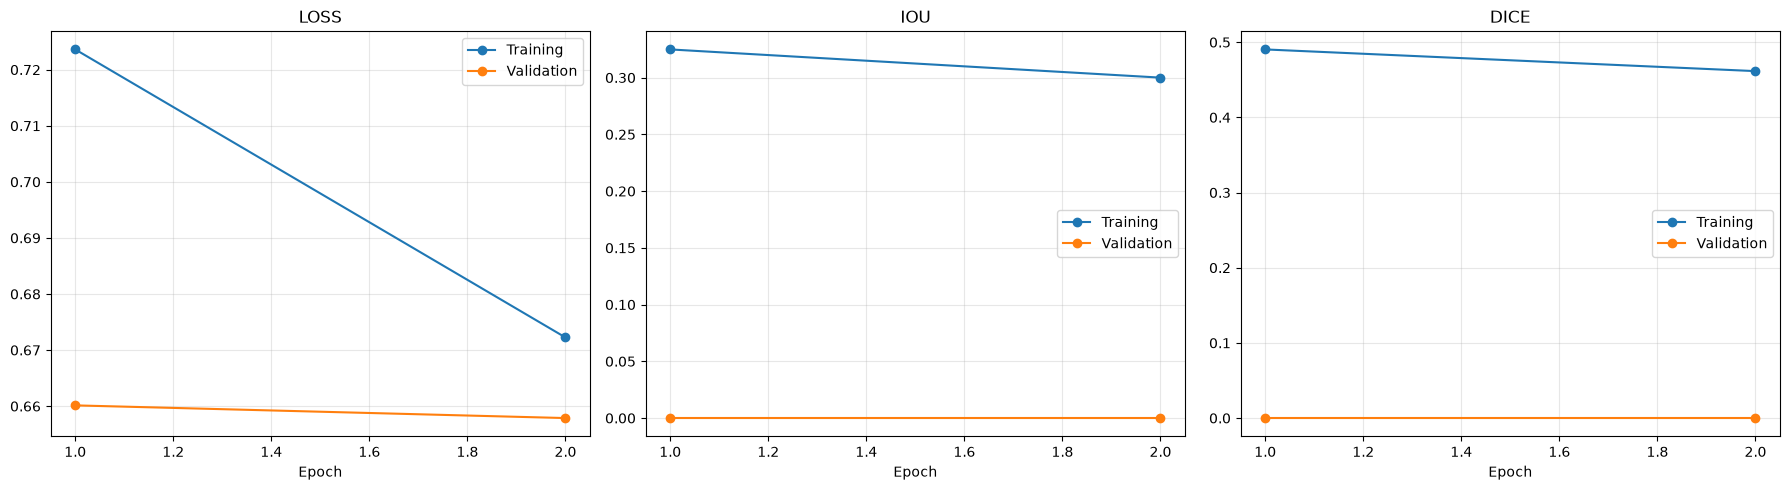

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, metric in zip(
    axes,
    ["loss", "iou", "dice"]
):

    ax.plot(
        results["epoch"],
        results[f"train_{metric}"],
        marker="o",
        label="Training"
    )

    ax.plot(
        results["epoch"],
        results[f"val_{metric}"],
        marker="o",
        label="Validation"
    )

    ax.set_title(metric.upper())
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    output_dir / "training_curves.png",
    dpi=150
)

plt.show()